# PCA on the card features

Goal: a shorter numeric vector for each card, to feed the model and to describe decks.

Rows are cards (the whole pool, not only the two decks). Columns are stats, a few flags, type / weakness / resistance indicators and the effect verbs from `tcg_bot.features`. Family and card kind are left out of the matrix; they reach the model separately.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path
from sklearn.decomposition import PCA
from tcg_bot.features import card_features, standardize, tag_effects, VERBS, STATS

sns.set_theme(style="whitegrid", context="notebook")
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
PROC = ROOT / "data" / "processed"
cards = pd.read_parquet(PROC / "cards.parquet")
moves = pd.read_parquet(PROC / "moves.parquet")
deck_cards = pd.read_parquet(PROC / "deck_cards.parquet")

X = card_features(cards, moves)
info = cards.set_index("card_id").loc[X.index]
is_pokemon = info["family"].eq("pokemon").to_numpy()
assert len(X) == len(cards) and X.index.is_unique
assert (X.nunique() > 1).all(), "a column is constant"
assert X.loc[~is_pokemon & ~info["is_fossil"].to_numpy(bool), "hp"].isna().all()      # fossils are Items with HP
print("cards x columns:", X.shape, "| missing cells (Trainer and Energy stats):", int(X.isna().sum().sum()))

cards x columns: (1431, 56) | missing cells (Trainer and Energy stats): 1873


## 1. Missing stats

Trainers and Energy cards have no HP or attack cost. Filling those with 0 makes the first component mostly answer "is this a Pokémon?", which we already know. Instead, each column is scaled using only the cards that have the value, and a missing value becomes 0 after scaling, so it pulls in no direction.

In [3]:
zero = X.fillna(0)
Z_zero = (zero - zero.mean()) / zero.std(ddof=0)
mean, std = X.mean(), X.std(ddof=0)
Z = standardize(X, mean, std)

for name, M in [("missing = 0", Z_zero), ("missing = neutral", Z)]:
    scores = PCA(3, svd_solver="full").fit_transform(M)
    corr = [abs(np.corrcoef(scores[:, i], is_pokemon)[0, 1]) for i in range(3)]
    print(f"{name:18s} |correlation with is_pokemon|  PC1 {corr[0]:.2f}  PC2 {corr[1]:.2f}  PC3 {corr[2]:.2f}")

missing = 0        |correlation with is_pokemon|  PC1 0.68  PC2 0.07  PC3 0.24
missing = neutral  |correlation with is_pokemon|  PC1 0.03  PC2 0.04  PC3 0.04


## 2. Is the data suited to PCA?

The Kaiser-Meyer-Olkin (KMO) measure asks how much of the correlation between columns is shared. A common reading is: below 0.5 poor, 0.6 to 0.7 mediocre, above 0.8 good. It is not designed for sets of indicator columns that exclude each other (a card has one type), so it is shown by block.

In [4]:
def kmo(M):
    R = np.corrcoef(M.to_numpy(), rowvar=False)
    S = np.linalg.pinv(R)
    partial = -S / np.sqrt(np.outer(np.diag(S), np.diag(S)))
    np.fill_diagonal(R, 0); np.fill_diagonal(partial, 0)
    return (R ** 2).sum() / ((R ** 2).sum() + (partial ** 2).sum())

types = [c for c in X if c.startswith(("type_", "weak_", "resist_"))]
verbs = list(VERBS)
stats_flags = [c for c in X if c not in types + verbs]
for name, cols in [("all columns", list(X)), ("stats and flags", stats_flags), ("effect verbs", verbs), ("type / weakness / resistance", types)]:
    print(f"{name:30s} {len(cols):2d} columns  KMO {kmo(Z[cols]):.2f}")

all columns                    56 columns  KMO 0.34
stats and flags                18 columns  KMO 0.67
effect verbs                   18 columns  KMO 0.46
type / weakness / resistance   20 columns  KMO 0.20


## 3. How many components, and which columns skip the PCA

**Parallel analysis** keeps a component only if it explains more than the same position does in shuffled data (95th percentile of 200 shuffles).

**Bypass rule:** a column that the kept components rebuild poorly (R² below 0.5) is taken out of the PCA and passed to the model unchanged. The PCA is refitted until no column falls under the line.

In [5]:
def parallel_analysis(M, n=200, q=95, seed=0):
    rng = np.random.default_rng(seed)
    A = M.to_numpy()
    eig = lambda B: np.linalg.eigvalsh(np.cov(B, rowvar=False))[::-1]
    real = eig(A)
    null = np.array([eig(np.column_stack([rng.permutation(col) for col in A.T])) for _ in range(n)])
    threshold = np.percentile(null, q, axis=0)
    above = real > threshold
    k = len(real) if above.all() else int(np.argmin(above))
    return k, real, threshold

def column_r2(M, k):
    p = PCA(k, svd_solver="full").fit(M)
    A, rebuilt = M.to_numpy(), p.inverse_transform(p.transform(M))
    return pd.Series(1 - ((A - rebuilt) ** 2).sum(0) / ((A - A.mean(0)) ** 2).sum(0), index=M.columns)

bypass = []
while True:
    bulk = [c for c in X if c not in bypass]
    k, eigenvalues, threshold = parallel_analysis(Z[bulk])
    r2 = column_r2(Z[bulk], k)
    new = list(r2[r2 < 0.5].index)
    print(f"{len(bulk)} columns in the PCA -> {k} components | newly below 0.5: {new}")
    if not new:
        break
    bypass += new

pca = PCA(k, svd_solver="full").fit(Z[bulk])
cumulative = np.cumsum(PCA(svd_solver="full").fit(Z[bulk]).explained_variance_ratio_)
print(f"\nPCA: {len(bulk)} columns -> {k} components, {cumulative[k - 1]:.1%} of their variance")
print(f"bypass ({len(bypass)}): {bypass}")
print(f"model input per card: {k} + {len(bypass)} = {k + len(bypass)}, down from {X.shape[1]}")

56 columns in the PCA -> 22 components | newly below 0.5: ['is_ace_spec', 'is_ancient', 'has_owner', 'switch_opp', 'heal', 'recoil', 'modify_stat', 'coin_flip']
48 columns in the PCA -> 21 components | newly below 0.5: ['status']
47 columns in the PCA -> 21 components | newly below 0.5: []

PCA: 47 columns -> 21 components, 79.6% of their variance
bypass (9): ['is_ace_spec', 'is_ancient', 'has_owner', 'switch_opp', 'heal', 'recoil', 'modify_stat', 'coin_flip', 'status']
model input per card: 21 + 9 = 30, down from 56


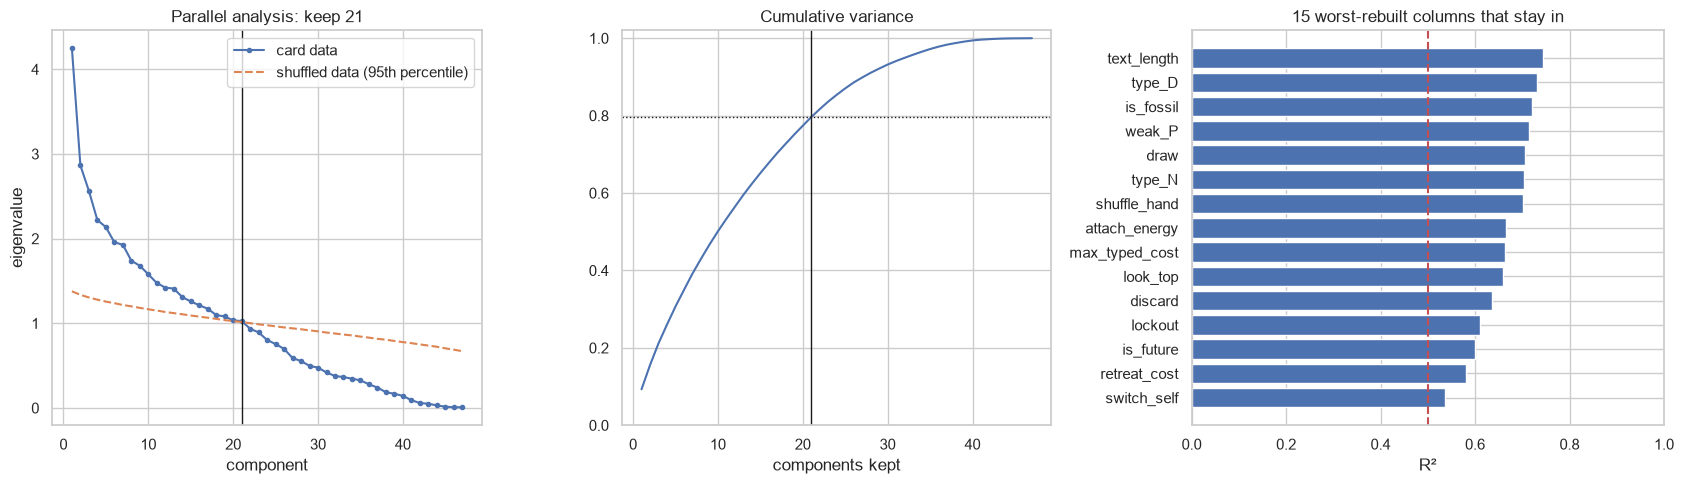

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [1, 1, 1.1]})
n = np.arange(1, len(eigenvalues) + 1)
axes[0].plot(n, eigenvalues, marker="o", ms=3, label="card data")
axes[0].plot(n, threshold, ls="--", label="shuffled data (95th percentile)")
axes[0].axvline(k, color="k", lw=1); axes[0].set_title(f"Parallel analysis: keep {k}")
axes[0].set_xlabel("component"); axes[0].set_ylabel("eigenvalue"); axes[0].legend()
axes[1].plot(np.arange(1, len(cumulative) + 1), cumulative)
axes[1].axvline(k, color="k", lw=1); axes[1].axhline(cumulative[k - 1], color="k", lw=1, ls=":")
axes[1].set_title("Cumulative variance"); axes[1].set_xlabel("components kept"); axes[1].set_ylim(0, 1.02)
worst = r2.sort_values().head(15)
axes[2].barh(worst.index, worst.values, color="#4c72b0"); axes[2].axvline(0.5, color="#c44e52", ls="--")
axes[2].set_title("15 worst-rebuilt columns that stay in"); axes[2].set_xlabel("R²"); axes[2].set_xlim(0, 1)
plt.tight_layout(); plt.show()

## 4. What the components mean

PC1 (9.3%): hp +0.39, is_ex +0.36, max_damage +0.36, max_cost +0.30, text_length +0.29, max_typed_cost +0.26
PC2 (6.3%): weak_R +0.44, resist_F -0.37, type_P -0.37, weak_D -0.36, resist_G +0.36, type_M +0.35
PC3 (5.6%): weak_D +0.37, type_P +0.36, resist_F +0.32, type_M +0.32, resist_G +0.32, weak_R +0.32
PC4 (4.9%): type_R +0.46, weak_W +0.46, weak_F -0.41, type_C -0.31, type_L -0.25, text_length -0.17
PC5 (4.7%): type_F +0.47, weak_G +0.44, type_R -0.40, weak_W -0.40, weak_P +0.27, type_D +0.18


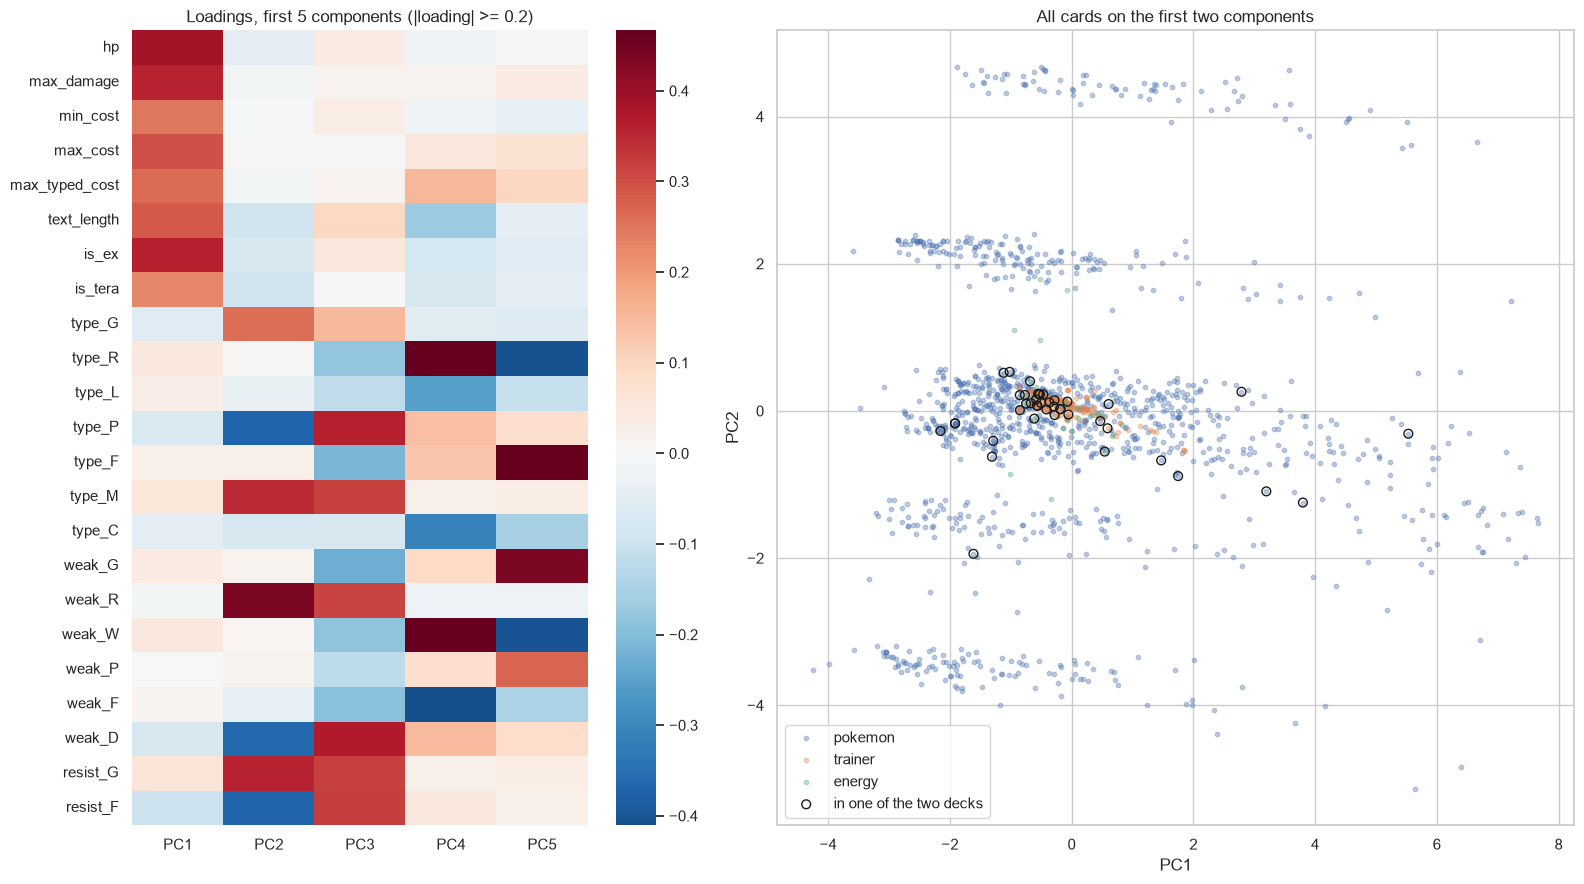

In [7]:
scores = pd.DataFrame(pca.transform(Z[bulk]), index=X.index, columns=[f"PC{i + 1}" for i in range(k)])
loadings = pd.DataFrame(pca.components_.T, index=bulk, columns=scores.columns)
for pc in scores.columns[:5]:
    top = loadings[pc].abs().sort_values(ascending=False).head(6).index
    print(pc, f"({pca.explained_variance_ratio_[int(pc[2:]) - 1]:.1%}):", ", ".join(f"{c} {loadings.at[c, pc]:+.2f}" for c in top))

shown = loadings.iloc[:, :5]
shown = shown[shown.abs().max(axis=1) >= 0.2]
fig, axes = plt.subplots(1, 2, figsize=(16, 9), gridspec_kw={"width_ratios": [1, 1.4]})
sns.heatmap(shown, cmap="RdBu_r", center=0, ax=axes[0]); axes[0].set_title("Loadings, first 5 components (|loading| >= 0.2)")
for fam, colour in [("pokemon", "#4c72b0"), ("trainer", "#dd8452"), ("energy", "#55a868")]:
    pick = info["family"].eq(fam)
    axes[1].scatter(scores.loc[pick, "PC1"], scores.loc[pick, "PC2"], s=10, alpha=0.35, color=colour, label=fam)
in_deck = scores.loc[deck_cards["card_id"].unique()]
axes[1].scatter(in_deck["PC1"], in_deck["PC2"], s=40, facecolor="none", edgecolor="k", label="in one of the two decks")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2"); axes[1].set_title("All cards on the first two components"); axes[1].legend()
plt.tight_layout(); plt.show()

## 5. Robustness

- **Bootstrap:** refit on resampled cards. The *subspace* score asks whether the same space is found; the per-component score asks whether each axis keeps its meaning.
- **FAMD-style variant:** weight the type / weakness / resistance indicators by 1 / sqrt(frequency), as mixed-data methods do, and see whether card neighbours change.
- **Neighbours:** how many of a card's 5 nearest cards in the full scaled table are still its nearest in the short vector.

In [8]:
rng = np.random.default_rng(0)
A = Z[bulk].to_numpy()
subspace, axis = [], []
for _ in range(100):
    b = PCA(k, svd_solver="full").fit(A[rng.integers(0, len(A), len(A))]).components_
    overlap = pca.components_ @ b.T
    subspace.append((np.linalg.svd(overlap, compute_uv=False) ** 2).mean())
    axis.append(np.abs(overlap).max(axis=1))
axis = np.median(axis, axis=0)
print(f"subspace stability {np.mean(subspace):.2f} (1 = identical)")
print("components that keep their meaning (median |cos| >= 0.8):", [f"PC{i + 1}" for i in range(k) if axis[i] >= 0.8])

def neighbours(M, n=5):
    V = np.asarray(M, dtype=float)
    V = V / np.clip(np.linalg.norm(V, axis=1, keepdims=True), 1e-9, None)
    S = V @ V.T
    np.fill_diagonal(S, -9)
    return np.argsort(-S, axis=1)[:, :n]

def shared(a, b):
    return np.mean([len(set(i) & set(j)) / len(i) for i, j in zip(a, b)])

famd = Z[bulk].copy()
for col in [c for c in bulk if c in types]:
    p = X[col].mean()
    famd[col] = (X[col] - p) / np.sqrt(p)
vectors = np.column_stack([scores, Z[bypass]])                # what the model would get
raw_nn = neighbours(Z)
print(f"PCA vs FAMD-style, shared neighbours: {shared(neighbours(pca.transform(Z[bulk])), neighbours(PCA(k, svd_solver='full').fit_transform(famd))):.2f}")
print(f"final vector vs full table, shared neighbours: {shared(neighbours(vectors), raw_nn):.2f}")

names = info["card_name"].to_numpy()
nn = neighbours(vectors, 4)
for name in ["Mega Lopunny ex", "Mega Lucario ex", "Riolu", "Solrock", "Ultra Ball", "Poké Pad", "Switch", "Boss's Orders"]:
    hit = np.flatnonzero(names == name)
    if len(hit):
        print(f"  {name:18s} -> {', '.join(names[j] for j in nn[hit[0]])}")

subspace stability 0.94 (1 = identical)
components that keep their meaning (median |cos| >= 0.8): ['PC1', 'PC2', 'PC3']
PCA vs FAMD-style, shared neighbours: 0.97
final vector vs full table, shared neighbours: 0.78
  Mega Lopunny ex    -> Mega Audino ex, Mega Kangaskhan ex, Mega Gengar ex, Mega Zeraora ex
  Mega Lucario ex    -> Regirock ex, Mega Hawlucha ex, Stunfisk ex, Mega Starmie ex
  Riolu              -> Meditite, Mankey, Timburr, Tyrogue
  Solrock            -> Claydol, Naclstack, Nacli, Rolycoly
  Ultra Ball         -> Larry's Skill, Canari, Perrin, Team Rocket's Proton
  Poké Pad           -> Crispin, Call Bell, Team Rocket's Proton, Ethan's Adventure
  Switch             -> Surfing Beach, Surfer, Ogre's Mask, Transformation Tome
  Boss's Orders      -> Repel, Pokémon Catcher, Bayleef, Cranidos


## 6. Save the fitted PCA and the card vectors

The PCA is fitted once on the whole pool and then frozen, so training and play use the same vectors. The last check lists cards in the two decks that the vector cannot tell apart.

In [9]:
card_vectors = pd.concat([scores, Z[bypass]], axis=1).reset_index()
card_vectors.to_parquet(PROC / "card_vectors.parquet", index=False)
joblib.dump({"columns": list(X), "mean": mean, "std": std, "bulk": bulk, "bypass": bypass, "pca": pca},
            PROC / "card_pca.joblib")

again = joblib.load(PROC / "card_pca.joblib")
Z_again = standardize(card_features(cards, moves)[again["columns"]], again["mean"], again["std"])
assert np.allclose(again["pca"].transform(Z_again[again["bulk"]]), scores)
print("saved", card_vectors.shape, "and card_pca.joblib")

deck_rows = card_vectors.set_index("card_id").loc[deck_cards["card_id"].unique()].round(6)
twins = deck_rows[deck_rows.duplicated(keep=False)]
print(f"deck cards: {len(deck_rows)} | sharing a vector with another deck card: {len(twins)}")
for _, group in twins.groupby(list(twins.columns)):
    print("   identical:", [info.at[i, "card_name"] for i in group.index])

saved (1431, 31) and card_pca.joblib
deck cards: 42 | sharing a vector with another deck card: 2
   identical: ['Dunsparce', 'Buneary']


## 7. PCA de las variables numéricas de los Pokémon (para el reporte)

Solo las 1,196 cartas de Pokémon y 9 variables numéricas. No hay datos faltantes ni indicadores de sí/no, así que es la parte de la base de datos para la que el PCA está pensado.

In [10]:
from scipy.stats import chi2

NUM = ["hp", "retreat_cost", "n_attacks", "n_abilities", "max_damage",
       "min_cost", "max_cost", "max_typed_cost", "text_length"]
P = X.loc[is_pokemon, NUM]
assert not P.isna().any().any()
Zp = (P - P.mean()) / P.std(ddof=0)
n_rows, n_vars = Zp.shape

R = np.corrcoef(Zp.to_numpy(), rowvar=False)
bartlett = -(n_rows - 1 - (2 * n_vars + 5) / 6) * np.log(np.linalg.det(R))
dof = n_vars * (n_vars - 1) // 2
print(f"{n_rows} cartas x {n_vars} variables | KMO {kmo(Zp):.2f} | Bartlett chi2 {bartlett:.0f}, gl {dof}, p {'< 0.001' if chi2.sf(bartlett, dof) < 0.001 else round(chi2.sf(bartlett, dof), 3)}")

pca_p = PCA(svd_solver="full").fit(Zp)
names_pc = [f"PC{i + 1}" for i in range(n_vars)]
variance = pd.DataFrame({"valor propio": pca_p.explained_variance_,
                         "varianza (%)": 100 * pca_p.explained_variance_ratio_,
                         "acumulada (%)": 100 * np.cumsum(pca_p.explained_variance_ratio_)}, index=names_pc)
variance.round(2)

1196 cartas x 9 variables | KMO 0.68 | Bartlett chi2 5471, gl 36, p < 0.001


,valor propio,varianza (%),acumulada (%)
PC1,3.71,41.24,41.24
PC2,1.87,20.81,62.06
PC3,1.00,11.05,73.10
PC4,0.68,7.52,80.62
PC5,0.60,6.63,87.25
PC6,0.53,5.88,93.13
PC7,0.31,3.40,96.53
PC8,0.20,2.23,98.76
PC9,0.11,1.24,100.00


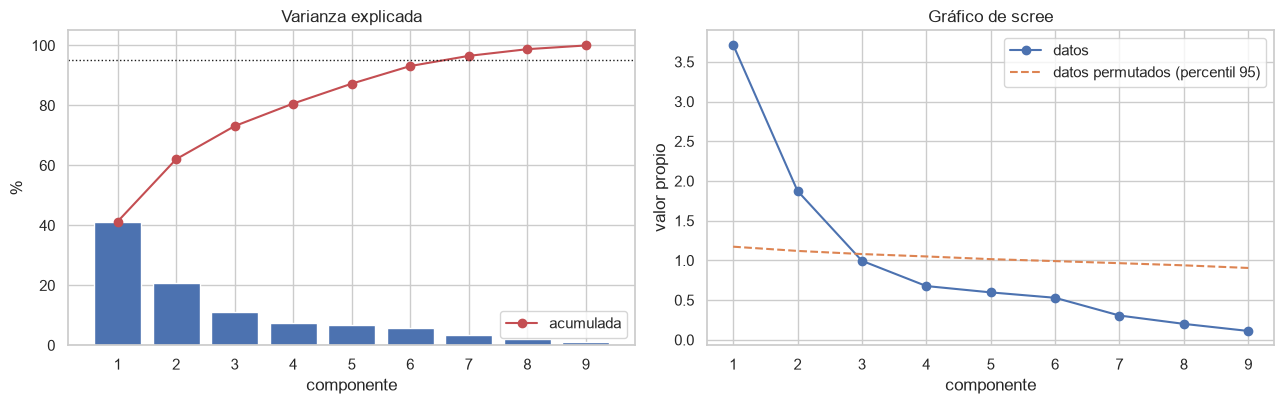

análisis paralelo: 2 componentes | al menos 95% de la varianza: 7 componentes


In [11]:
# Varianza explicada y gráfico de scree con análisis paralelo
k_par, eig_p, thr_p = parallel_analysis(Zp)
x = np.arange(1, n_vars + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].bar(x, variance["varianza (%)"], color="#4c72b0")
axes[0].plot(x, variance["acumulada (%)"], color="#c44e52", marker="o", label="acumulada")
axes[0].axhline(95, ls=":", color="k", lw=1); axes[0].set_xticks(x)
axes[0].set_title("Varianza explicada"); axes[0].set_xlabel("componente"); axes[0].set_ylabel("%"); axes[0].legend()
axes[1].plot(x, eig_p, marker="o", label="datos")
axes[1].plot(x, thr_p, ls="--", label="datos permutados (percentil 95)")
axes[1].set_xticks(x); axes[1].set_title("Gráfico de scree"); axes[1].set_xlabel("componente"); axes[1].set_ylabel("valor propio"); axes[1].legend()
plt.tight_layout(); plt.show()
k95 = int(np.argmax(variance["acumulada (%)"].to_numpy() >= 95)) + 1
print(f"análisis paralelo: {k_par} componentes | al menos 95% de la varianza: {k95} componentes")

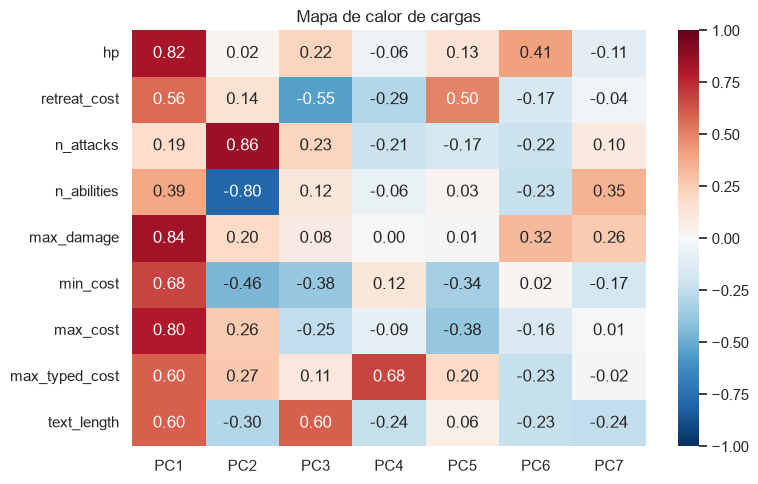

,PC1,PC2,PC3,PC4,PC5,PC6,PC7
hp,0.82,0.02,0.22,-0.06,0.13,0.41,-0.11
retreat_cost,0.56,0.14,-0.55,-0.29,0.50,-0.17,-0.04
n_attacks,0.19,0.86,0.23,-0.21,-0.17,-0.22,0.10
n_abilities,0.39,-0.80,0.12,-0.06,0.03,-0.23,0.35
max_damage,0.84,0.20,0.08,0.00,0.01,0.32,0.26
min_cost,0.68,-0.46,-0.38,0.12,-0.34,0.02,-0.17
max_cost,0.80,0.26,-0.25,-0.09,-0.38,-0.16,0.01
max_typed_cost,0.60,0.27,0.11,0.68,0.20,-0.23,-0.02
text_length,0.60,-0.30,0.60,-0.24,0.06,-0.23,-0.24


In [12]:
# Cargas = correlación entre cada variable y cada componente
loadings_p = pd.DataFrame(pca_p.components_.T * np.sqrt(pca_p.explained_variance_ * (n_rows - 1) / n_rows),
                          index=NUM, columns=names_pc)
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(loadings_p.iloc[:, :k95], annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Mapa de calor de cargas"); plt.tight_layout(); plt.show()
loadings_p.iloc[:, :k95].round(2)

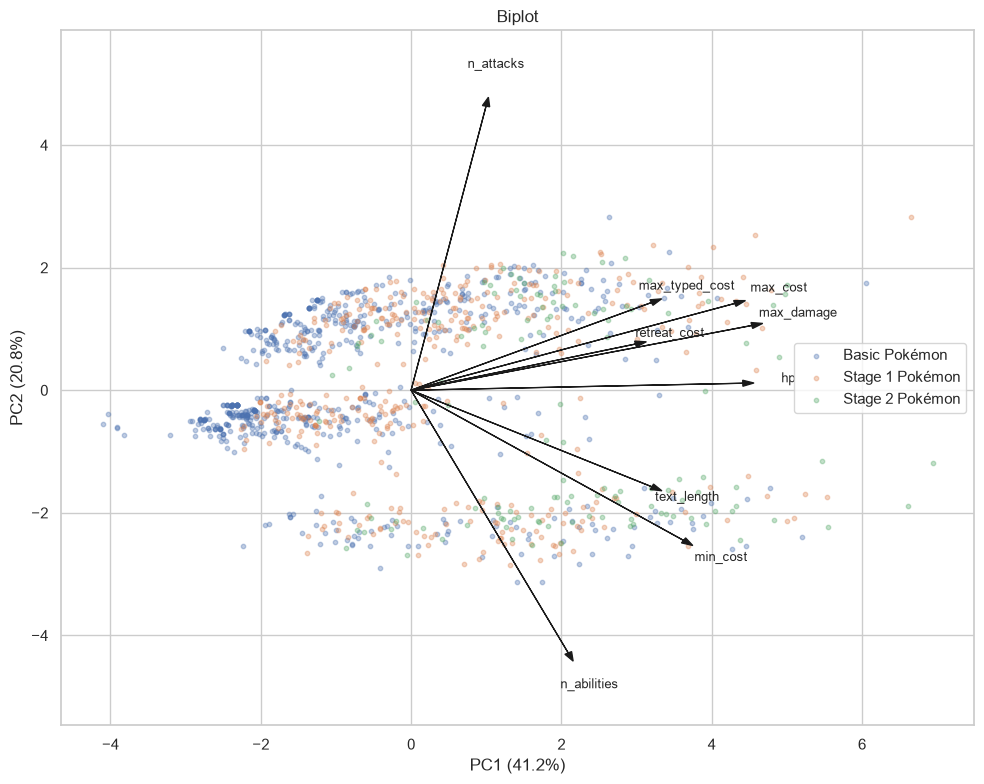

In [13]:
# Biplot: cartas y variables en los dos primeros componentes
scores_p = pd.DataFrame(pca_p.transform(Zp), index=P.index, columns=names_pc)
stage = info.loc[P.index, "card_kind"].astype(str)
colours = {"Basic Pokémon": "#4c72b0", "Stage 1 Pokémon": "#dd8452", "Stage 2 Pokémon": "#55a868"}

fig, ax = plt.subplots(figsize=(10, 8))
for kind, colour in colours.items():
    pick = stage.eq(kind)
    ax.scatter(scores_p.loc[pick, "PC1"], scores_p.loc[pick, "PC2"], s=10, alpha=0.35, color=colour, label=kind)
scale = 0.8 * scores_p[["PC1", "PC2"]].abs().to_numpy().max()
for var in NUM:
    dx, dy = scale * loadings_p.at[var, "PC1"], scale * loadings_p.at[var, "PC2"]
    ax.arrow(0, 0, dx, dy, color="k", lw=0.9, head_width=0.1, length_includes_head=True)
    ax.text(dx * 1.1, dy * 1.1, var, fontsize=9, ha="center")
ax.set_xlabel(f"PC1 ({variance.at['PC1', 'varianza (%)']:.1f}%)"); ax.set_ylabel(f"PC2 ({variance.at['PC2', 'varianza (%)']:.1f}%)")
ax.set_ylim(*(np.array(ax.get_ylim()) * 1.12)); ax.set_title("Biplot"); ax.legend(loc="center right"); plt.tight_layout(); plt.show()

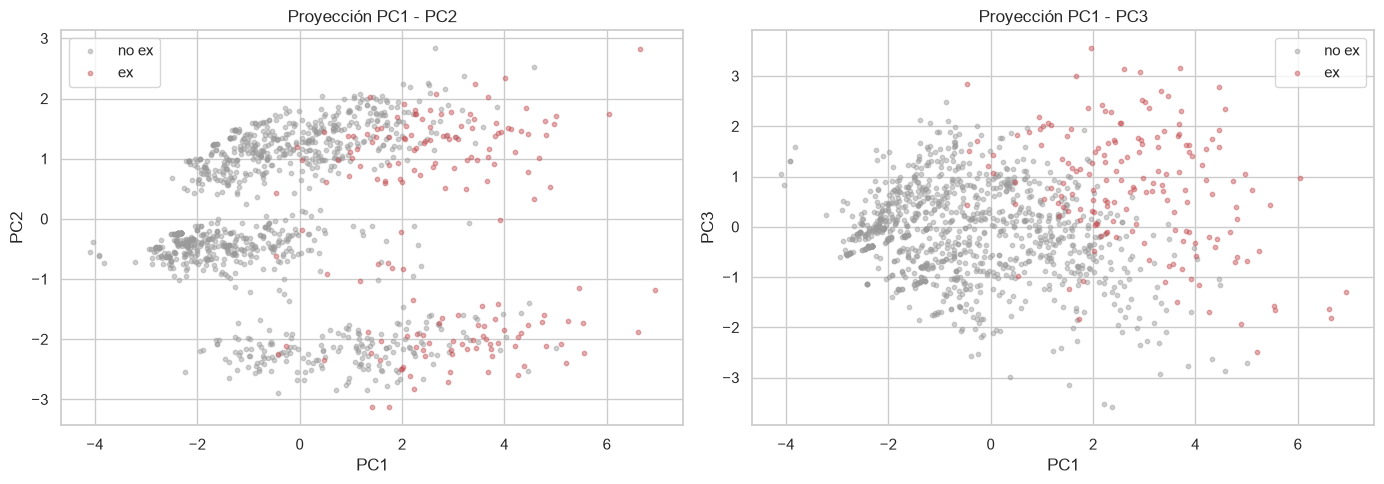

In [14]:
# Proyecciones: ¿se separan las cartas ex?
is_ex = info.loc[P.index, "has_rule_box"].astype(bool)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, other in zip(axes, ["PC2", "PC3"]):
    for flag, colour, label in [(False, "#9a9a9a", "no ex"), (True, "#c44e52", "ex")]:
        pick = is_ex.eq(flag)
        ax.scatter(scores_p.loc[pick, "PC1"], scores_p.loc[pick, other], s=10, alpha=0.45, color=colour, label=label)
    ax.set_xlabel("PC1"); ax.set_ylabel(other); ax.set_title(f"Proyección PC1 - {other}"); ax.legend()
plt.tight_layout(); plt.show()

## 8. Modelo: ¿es la carta un Pokémon ex? Variables originales contra componentes

Regresión logística. El escalado y el PCA se ajustan **solo con los pliegues de entrenamiento**, y las cartas con el mismo nombre quedan del mismo lado, para no filtrar información. Se repite con 5 particiones distintas. Las columnas `is_ex`, `is_mega` y `has_rule_box` no son entradas.

Pokémon ex: 167 de 1196 | responder siempre 'no ex' da exactitud 0.860


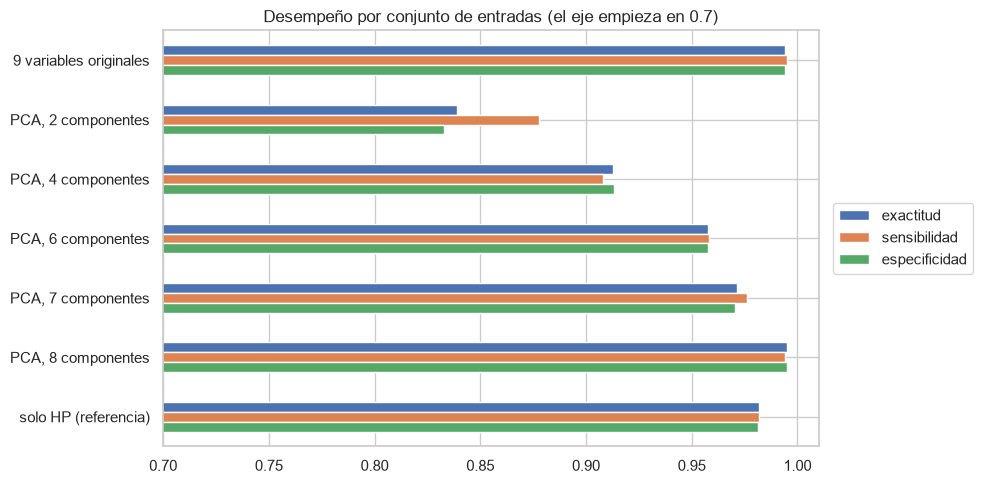

,exactitud,sensibilidad,especificidad
9 variables originales,0.994,0.995,0.994
"PCA, 2 componentes",0.839,0.878,0.833
"PCA, 4 componentes",0.913,0.908,0.913
"PCA, 6 componentes",0.958,0.958,0.958
"PCA, 7 componentes",0.971,0.976,0.970
"PCA, 8 componentes",0.995,0.994,0.995
solo HP (referencia),0.982,0.982,0.982


In [15]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import confusion_matrix

y = is_ex.astype(int).to_numpy()
groups = info.loc[P.index, "card_name"].to_numpy()

def evaluate(columns, n_components=None, seeds=range(5)):
    out = []
    for seed in seeds:
        steps = [StandardScaler()] + ([PCA(n_components, svd_solver="full")] if n_components else [])
        model = make_pipeline(*steps, LogisticRegression(max_iter=5000, class_weight="balanced"))
        folds = list(StratifiedGroupKFold(5, shuffle=True, random_state=seed).split(P, y, groups))
        tn, fp, fn, tp = confusion_matrix(y, cross_val_predict(model, P[columns].to_numpy(), y, cv=folds)).ravel()
        out.append({"exactitud": (tp + tn) / len(y), "sensibilidad": tp / (tp + fn), "especificidad": tn / (tn + fp)})
    return pd.DataFrame(out).mean()

results = {"9 variables originales": evaluate(NUM)}
for k_i in [2, 4, 6, 7, 8]:
    results[f"PCA, {k_i} componentes"] = evaluate(NUM, k_i)
results["solo HP (referencia)"] = evaluate(["hp"])
results = pd.DataFrame(results).T
print(f"Pokémon ex: {y.sum()} de {len(y)} | responder siempre 'no ex' da exactitud {1 - y.mean():.3f}")
ax = results.plot.barh(figsize=(10, 5), xlim=(0.7, 1.01)); ax.invert_yaxis()
ax.set_title("Desempeño por conjunto de entradas (el eje empieza en 0.7)"); ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5)); plt.tight_layout(); plt.show()
results.round(3)

**Lectura.** Compara la fila de 7 componentes (la menor cantidad que conserva al menos 95% de la varianza) con las 9 variables originales: el PCA pierde un poco de exactitud a cambio de usar menos entradas; no mejora el modelo. La tarea además es fácil, porque HP por sí solo ya clasifica casi todo. Otra limitación: las filas de la regla Tera solo aparecen en cartas ex y suman caracteres a `text_length`.

## What this establishes, and what it does not

- The short vector is a moderate reduction, not a dramatic one: the effect verbs are close to independent of each other, so they compress little.
- KMO is low over all columns. PCA is justified here by the reduction and the neighbour checks, not by strong factor structure.
- Only the first few components can be named. The model uses the space as a whole.
- Effects are described by verbs only: no amounts and no filters, so a search for Basic Pokémon and a search for Energy can look alike.
- Verbs come from the regex patterns; the hand-labelled holdout has not been scored yet.
- Whether PCA helps the model play better is not tested here. That needs the ablation (PCA, PCA plus bypass, raw columns, learned embedding).

## 7. PCA on the numeric Pokémon variables (for the report)

Only the 1,196 Pokémon cards and 9 numeric variables. There is no missing data and there are no yes/no indicators, so this is the part of the dataset that PCA is designed for.

### Interpretation and component selection

**Transformation.** The 9 variables are standardised (mean 0, standard deviation 1) because their scales differ widely: HP reaches the hundreds while costs are only a few units.

**Components.**

- **PC1 (41.2%): card strength.** All loadings are positive; the largest are `max_damage` (0.84), `hp` (0.82) and `max_cost` (0.80). Cards with more HP, more damage and more expensive attacks sit on the right.
- **PC2 (20.8%): attacks versus abilities.** `n_attacks` (0.86) points the opposite way to `n_abilities` (−0.80). This produces three bands: two attacks and no ability (558 cards), one attack and no ability (394), and one attack with one ability (244).
- **PC3 (11.0%): long text versus retreat cost.** `text_length` (0.60) and `retreat_cost` (−0.55). It is harder to interpret than the first two.

**How many components to keep.**

| Criterion | Components | Cumulative variance |
|---|---|---|
| Parallel analysis | 2 | 62.1% |
| Kaiser (eigenvalue > 1; PC3 = 0.995) | 2 | 62.1% |
| At least 95% of the variance | 7 | 96.5% |

Two components are enough to describe and plot the data. The classifier compares 2, 4, 6, 7 and 8.

**Projections.** ex cards concentrate at high PC1 values (mean 2.85 against −0.46 for the rest), with some overlap. PC2 does not separate them (−0.11 against 0.02). Colouring by stage also shows heavy overlap.


## 8. Model: is the card a Pokémon ex? Original variables versus components

Logistic regression. Scaling and PCA are fitted **on the training folds only**, and cards with the same name stay on the same side, to avoid leaking information. This is repeated with 5 different splits. The columns `is_ex`, `is_mega` and `has_rule_box` are not inputs.

**Reading the results.** Compare the 7-component row (the fewest that keep at least 95% of the variance) with the 9 original variables: PCA loses a little accuracy in exchange for fewer inputs; it does not improve the model. The task is also easy, because HP alone already classifies almost everything. Another limitation: the Tera rule rows appear only on ex cards and add characters to `text_length`.